# Fine-tuning BERT cho NER — LAB09

Notebook đọc kết quả **đã chạy thật** trong `predictions/` và `results.csv`.
Phần huấn luyện nằm trong `ner_finetuning.py`; cell cuối chỉ chạy lại khi bật
`RUN_TRAINING = True`.

Kiến trúc: `H ∈ R^(T×768)` -> `Z = H W + b`, `Z ∈ R^(T×9)` -> BIO.

In [1]:
import json

import pandas as pd
from IPython.display import Image, display

from ner_utils import LABELS, read_json

pd.set_option("display.width", 140)
main = read_json("predictions/transformer_main_metrics.json")
baseline = read_json("predictions/baseline_metrics.json")
print("model:", main["model"], "| device:", main["device"])
print("strategy:", main["strategy"], "| max_len:", main["max_len"],
      "| batch:", main["batch_size"], "| lr:", main["learning_rate"])
print("best epoch:", main["best_epoch"], "| best dev entity F1:",
      round(main["best_dev_entity_f1"], 4))

model: google-bert/bert-base-cased | device: cuda
strategy: first | max_len: 128 | batch: 16 | lr: 3e-05
best epoch: 3 | best dev entity F1: 0.9486


## 1. Learning curves (3 epochs, real log)

,epoch,train_loss,dev_loss,dev_token_accuracy,dev_token_f1,dev_entity_precision,dev_entity_recall,dev_entity_f1,train_seconds
0,1,0.2008,0.0382,0.9894,0.9515,0.9366,0.9404,0.9385,203.9
1,2,0.0258,0.0359,0.9908,0.9566,0.9433,0.9472,0.9452,202.0
2,3,0.0120,0.0358,0.9913,0.9593,0.9460,0.9514,0.9486,198.9


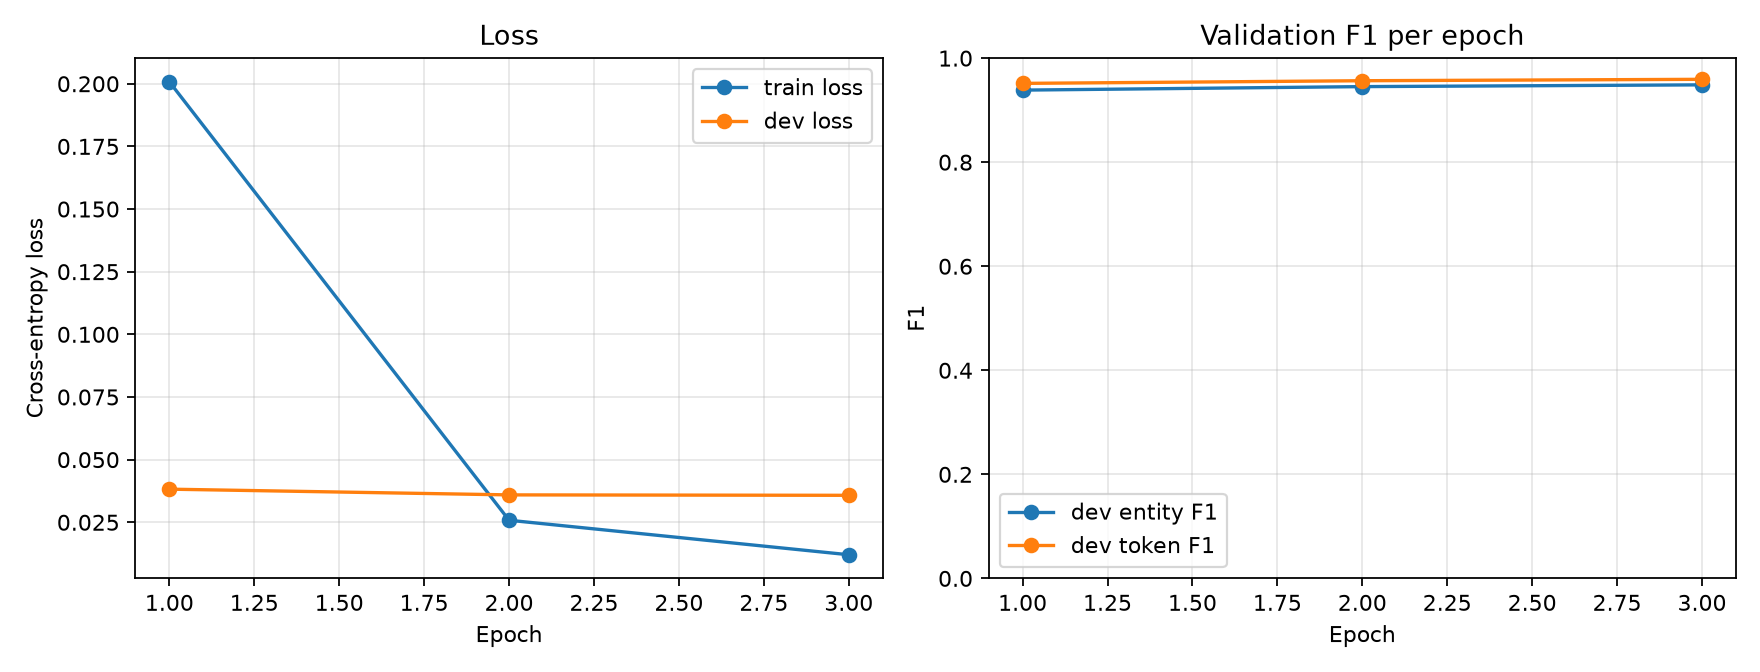

In [2]:
history = pd.DataFrame(main["history"])
display(history.round(4))
display(Image("learning_curves.png"))

## 2. Baseline vs Transformer

Cùng test set, entity-level P/R/F1. Token accuracy được báo cáo thêm nhưng
không dùng để kết luận vì nó bị chi phối bởi lớp `O`.

In [3]:
results = pd.read_csv("results.csv")
display(results)

,model,split,precision,recall,f1,token_accuracy,token_f1,support,predicted,n_sentences,n_tokens
0,Baseline (token features + logistic regression),test,0.7142,0.7757,0.7437,0.9575,0.8032,5648,6134,3453,46435
1,BERT-base-cased fine-tuned (Strategy A: first ...,test,0.9072,0.9189,0.9130,0.9824,0.9237,5648,5721,3453,46435
2,BERT-base-cased fine-tuned (Strategy B: propag...,test,0.9071,0.9212,0.9141,0.9832,0.9268,5648,5736,3453,46435


## 3. Entity-level evaluation theo loại entity

Một entity chỉ được tính TP khi **boundary và type** đều đúng.

In [4]:
entity_metrics = pd.read_csv("entity_metrics.csv")
display(entity_metrics[entity_metrics["group"] == "type"].round(4))

,group,entity,support,predicted,tp,fp,fn,precision,recall,f1
0,type,OVERALL,5648,5721,5190,531,458,0.9072,0.9189,0.9130
1,type,PER,1617,1617,1551,66,66,0.9592,0.9592,0.9592
2,type,ORG,1661,1718,1519,199,142,0.8842,0.9145,0.8991
3,type,LOC,1668,1654,1543,111,125,0.9329,0.9251,0.9290
4,type,MISC,702,732,577,155,125,0.7883,0.8219,0.8047


## 4. Entity-level F1 theo độ dài entity

,group,entity,support,predicted,tp,fp,fn,precision,recall,f1
5,length,1,3574,3605,3265,340,309,0.9057,0.9135,0.9096
6,length,2,1776,1800,1657,143,119,0.9206,0.9330,0.9267
7,length,3,236,246,211,35,25,0.8577,0.8941,0.8755
8,length,4+,62,70,57,13,5,0.8143,0.9194,0.8636


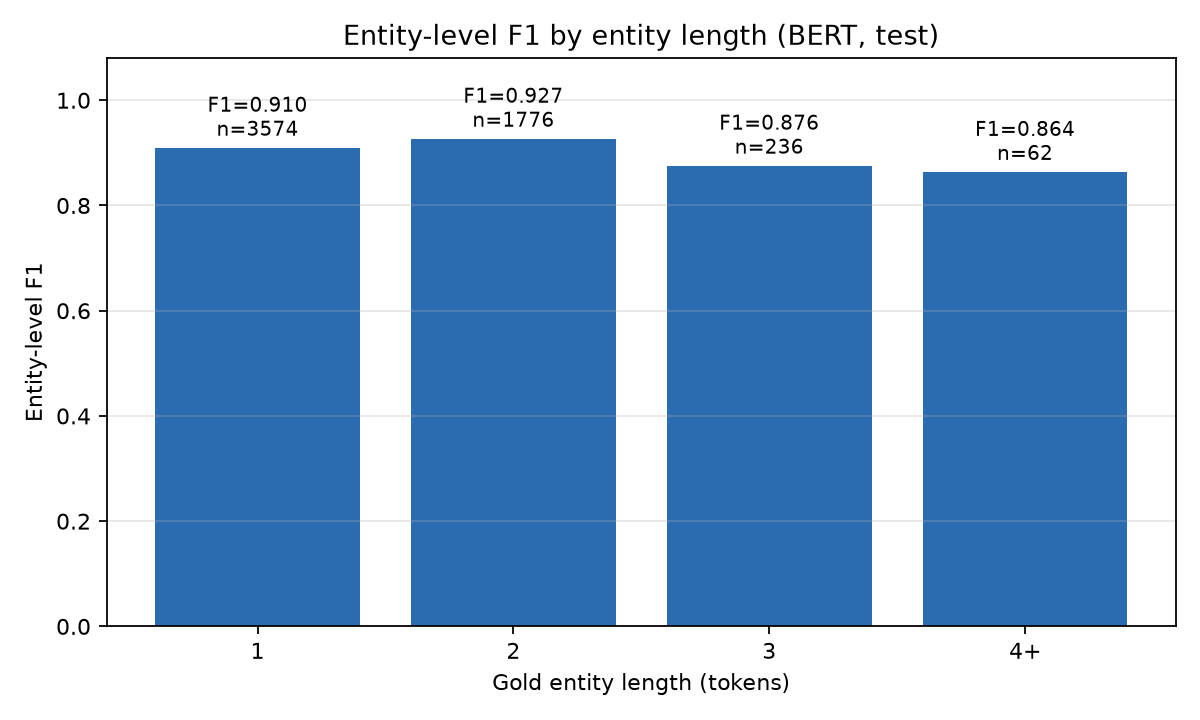

In [5]:
display(entity_metrics[entity_metrics["group"] == "length"].round(4))
display(Image("entity_length_analysis.png"))

## 5. Token-level confusion matrix

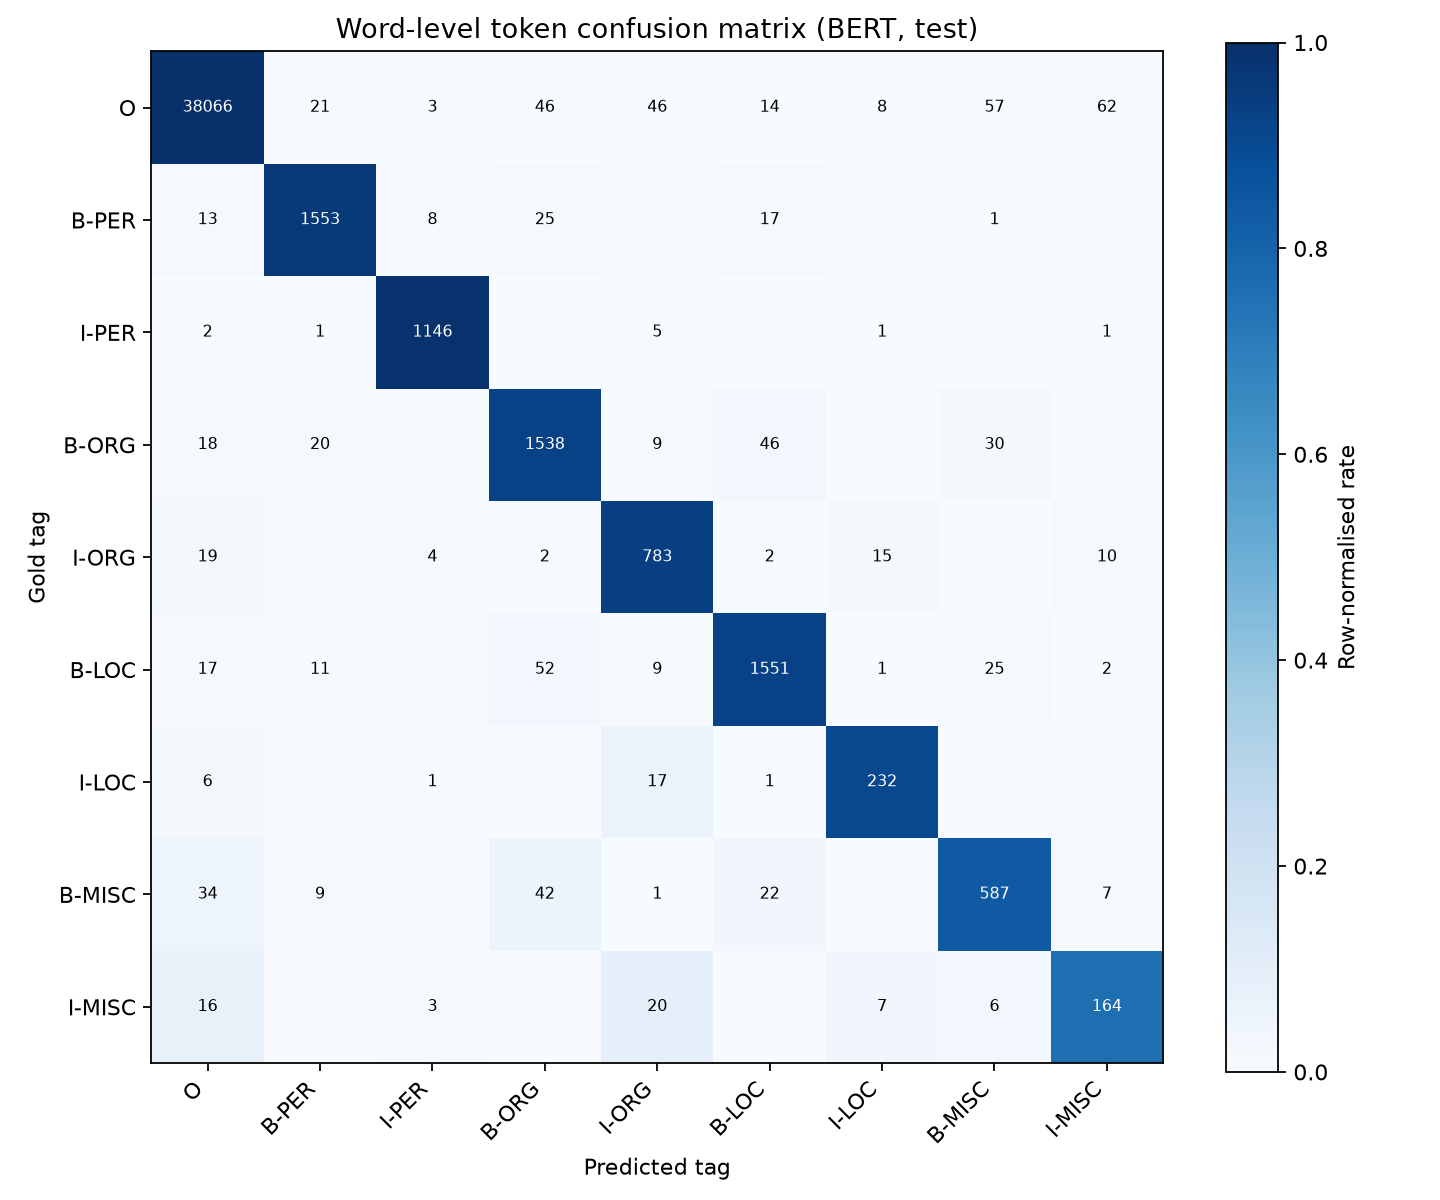

In [6]:
display(Image("confusion_matrix.png"))

## 6. Alignment ablation — ảnh hưởng của Strategy A vs B

Hai lần chạy cùng hyperparameter, chỉ khác nhãn của các subword tiếp nối
(`IGNORE` so với `I-X`).

In [7]:
ablation = pd.read_csv("alignment_ablation.csv")
display(ablation)

,strategy,epochs,best_epoch,best_dev_entity_f1,test_entity_f1,test_precision,test_recall,subwords_per_word,split_words,truncated_sentences,train_seconds,notes
0,A: first subword (IGNORE rest),3,3,0.9486,0.9130,0.9072,0.9189,1.3385,34288,1,630.9,"3 epochs, same hyperparameters"
1,B: propagate I-X,3,3,0.9492,0.9141,0.9071,0.9212,1.3385,34288,1,636.1,"3 epochs, same hyperparameters"


## 7. Ứng dụng: NER -> structured information extraction

In [8]:
from information_extraction import extract, load_model

tokenizer, model, device = load_model()
import torch
example_tokens = tokenizer(["Barack", "Obama", "visited", "Paris", "."],
                           is_split_into_words=True,return_tensors="pt")
with torch.inference_mode():
    logits = model(input_ids=example_tokens["input_ids"].to(device),
                   attention_mask=example_tokens["attention_mask"].to(device)).logits
print("logits shape:",tuple(logits.shape))
print("first-token logits:",logits[0,1].float().cpu().tolist())
print("token predictions:",[LABELS[i] for i in logits[0].argmax(-1).tolist()])
demo = extract(
    "Barack Obama visited Paris to meet Microsoft executives. "
    "The United Nations Security Council met in New York.",
    tokenizer, model, device,
)
print(json.dumps(demo["entities"], ensure_ascii=False, indent=2))

C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


logits shape: (1, 7, 9)
first-token logits: [-1.1332405805587769, 7.864765167236328, -0.7291037440299988, -0.1053711399435997, -1.8127474784851074, 0.1383938491344452, -1.4850223064422607, 0.029876433312892914, -2.552374839782715]
token predictions: ['O', 'B-PER', 'I-PER', 'O', 'B-LOC', 'O', 'O']
{
  "PERSON": [
    "Barack Obama"
  ],
  "ORGANIZATION": [
    "Microsoft",
    "United Nations Security Council"
  ],
  "LOCATION": [
    "Paris",
    "New York"
  ],
  "MISC": []
}


## 8. Error examples

In [9]:
errors = read_json("predictions/error_examples.json")
print("summary:", json.dumps(errors["summary"], indent=2))
display(pd.DataFrame(errors["false_positives"])[
    ["text", "gold", "prediction", "error_type", "explanation"]
])
display(pd.DataFrame(errors["false_negatives"])[
    ["text", "gold", "prediction", "error_type", "explanation"]
])

summary: {
  "n_sentences": 3453,
  "false_positives": 531,
  "false_negatives": 458,
  "boundary_pairs": 169,
  "fp_error_types": {
    "wrong entity type": 311,
    "spurious entity": 148,
    "wrong boundary": 72
  },
  "fn_error_types": {
    "wrong entity type": 312,
    "wrong boundary": 76,
    "missing entity": 70
  },
  "rare_entity_fn": 292,
  "seen_entity_fn": 166
}


,text,gold,prediction,error_type,explanation
0,"SOCCER - JAPAN GET LUCKY WIN, CHINA IN SURPRIS...",JAPAN,JAPAN (PER),wrong entity type,The span matches a gold LOC entity ('JAPAN') b...
1,Burmese troops and riot police moved in to dis...,Ranyon ( Rangoon ) University,Ranyon (ORG),wrong boundary,"Gold 'Ranyon ( Rangoon ) University' (ORG, 5 t..."
2,"SOCCER - JAPAN GET LUCKY WIN, CHINA IN SURPRIS...",O,LUCKY (LOC),spurious entity,No gold entity overlaps this span; the model t...
3,"SOCCER - JAPAN GET LUCKY WIN, CHINA IN SURPRIS...",CHINA,CHINA (ORG),wrong entity type,The span matches a gold PER entity ('CHINA') b...
4,Defender Hassan Abbas rose to intercept a long...,Bitar,Bitar (ORG),wrong entity type,The span matches a gold PER entity ('Bitar') b...


,text,gold,prediction,error_type,explanation
0,"SOCCER - JAPAN GET LUCKY WIN, CHINA IN SURPRIS...",JAPAN (LOC),JAPAN (PER),wrong entity type,Gold LOC 'JAPAN' overlaps a predicted PER span...
1,"SOCCER - JAPAN GET LUCKY WIN, CHINA IN SURPRIS...",CHINA (PER),CHINA (ORG),wrong entity type,Gold PER 'CHINA' overlaps a predicted ORG span...
2,Cuttitta announced his retirement after the 19...,1995 World Cup (MISC),World Cup (MISC),wrong boundary,"Gold span [6,9) vs predicted [7,9); overlap 2/..."
3,"FIFA's players' status committee, meeting in B...",Udinese (ORG),Udinese (MISC),wrong entity type,Gold ORG 'Udinese' overlaps a predicted MISC s...
4,"Blinker was fined 75,000 Swiss francs ( $ 57,6...",Engllsh (MISC),Engllsh (ORG),wrong entity type,Gold MISC 'Engllsh' overlaps a predicted ORG s...


## 9. Tuỳ chọn chạy lại huấn luyện

Mặc định tắt để notebook mở ra là xem được ngay và không train ngoài ý muốn.
Bật `RUN_TRAINING = True` sẽ chạy 3 epoch (~10 phút trên RTX 4060) và ghi đè
checkpoint/kết quả.

In [10]:
RUN_TRAINING = False
if RUN_TRAINING:
    import ner_finetuning
    ner_finetuning.train(ner_finetuning.parse_args([]))
else:
    print("Skipped. Set RUN_TRAINING = True to re-run the 3-epoch fine-tuning.")

Skipped. Set RUN_TRAINING = True to re-run the 3-epoch fine-tuning.
